In [2]:
import pandas as pd, os
b = r"C:\Users\TB Val 03\Desktop\PAULA PROYECTOS\MLproject\proyecto_sort\data"

for f in os.listdir(b):
    if f.endswith(".csv"):
        x = pd.read_csv(os.path.join(b, f), low_memory=False)
        print("\n=====", f, x.shape)
        print(list(x.columns)[:25])
        print(x.head(3).to_string()[:1500])


===== affect_features_and_labels_folded_all_timesteps.csv (48556, 117)
['rowid', 'clip_id', 'clip_sequence', 'confusion', 'concentration', 'boredom', 'frustration', 'on_task', 'off_task', 'fold', 'user_id', 'clip_sequence_id', 'avg_attemptCount', 'avg_bottomHint', 'avg_correct', 'avg_frIsHelpRequest', 'avg_frPast5HelpRequest', 'avg_frPast5WrongCount', 'avg_frPast8HelpRequest', 'avg_frPast8WrongCount', 'avg_frWorkingInSchool', 'avg_hint', 'avg_hintCount', 'avg_hintTotal', 'avg_original']
   rowid  clip_id  clip_sequence  confusion  concentration  boredom  frustration  on_task  off_task  fold  user_id  clip_sequence_id  avg_attemptCount  avg_bottomHint  avg_correct  avg_frIsHelpRequest  avg_frPast5HelpRequest  avg_frPast5WrongCount  avg_frPast8HelpRequest  avg_frPast8WrongCount  avg_frWorkingInSchool  avg_hint  avg_hintCount  avg_hintTotal  avg_original  avg_past8BottomOut  avg_scaffold  avg_stlHintUsed  avg_timeSinceSkill  avg_timeTaken  avg_totalFrAttempted  avg_totalFrPastWrongCount 

In [3]:
import os
import pandas as pd

# Tu ruta de datos
b = r"C:\Users\TB Val 03\Desktop\PAULA PROYECTOS\MLproject\proyecto_sort\data"

# Nombre exacto del archivo principal que acordamos usar
nombre_archivo = "affect_features_and_labels_folded_all_timesteps.csv"
ruta_completa = os.path.join(b, nombre_archivo)

# 1. Cargar el archivo en un DataFrame principal llamado df
df = pd.read_csv(ruta_completa, low_memory=False)

# Ver las dimensiones totales (filas y columnas)
print("Dimensiones del DataFrame:", df.shape)

# 2. Ver las primeras 5 filas de las columnas más importantes (ej. ID, fold y algunas features)
columnas_muestra = ['user_id', 'fold', 'frustration', 'avg_attemptCount', 'avg_timeTaken']
print("\n--- Vista previa de columnas clave ---")
print(df[columnas_muestra].head())


Dimensiones del DataFrame: (48556, 117)

--- Vista previa de columnas clave ---
   user_id  fold  frustration  avg_attemptCount  avg_timeTaken
0    72738     0          NaN               1.0        119.747
1    72738     0          NaN               1.0         22.359
2    72738     0          NaN               1.0         33.469
3    72738     0          0.0               1.0         37.422
4    72738     0          NaN               1.0         47.797


In [4]:
# Lista de posibles columnas de targets que aparecen en tus columnas
columnas_objetivo = [
    'frustration', 'frustration_1', 'frustration_2', 'frustration_3',
    'boredom', 'boredom_1', 'boredom_2', 'boredom_3',
    'confusion', 'confusion_1', 'confusion_2', 'confusion_3'
]

# Ver cuántos valores no nulos (válidos) tiene cada una
for col in columnas_objetivo:
    if col in df.columns:
        validos = df[col].notna().sum()
        print(f"Columna '{col}': {validos} registros válidos (no nulos)")

Columna 'frustration': 3111 registros válidos (no nulos)
Columna 'frustration_1': 748 registros válidos (no nulos)
Columna 'frustration_2': 599 registros válidos (no nulos)
Columna 'frustration_3': 1764 registros válidos (no nulos)
Columna 'boredom': 3111 registros válidos (no nulos)
Columna 'boredom_1': 748 registros válidos (no nulos)
Columna 'boredom_2': 599 registros válidos (no nulos)
Columna 'boredom_3': 1764 registros válidos (no nulos)
Columna 'confusion': 3111 registros válidos (no nulos)
Columna 'confusion_1': 748 registros válidos (no nulos)
Columna 'confusion_2': 599 registros válidos (no nulos)
Columna 'confusion_3': 1764 registros válidos (no nulos)


In [5]:
emo = ["confusion", "concentration", "boredom", "frustration"]
df_emo = df.dropna(subset=emo, how="all")
df_multi = df_emo[df_emo[emo].sum(axis=1) == 1].copy()   # 3.093 filas 
df_multi["target"] = df_multi[emo].idxmax(axis=1)
print(df_multi["target"].value_counts())

target
concentration    2552
boredom           308
confusion         121
frustration       112
Name: count, dtype: int64


In [6]:
# 1. Forzar a Pandas a mostrar todas las filas (columnas) sin recortar con "..."
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

# Seleccionamos solo las columnas numéricas (excluyendo IDs, folds y targets si ya están separados)
# Si usas tu df_clean actual, puedes calcular el describe de las features:
estadisticas = df_multi.describe().T  # .T traspone la tabla para verla más cómoda en vertical

# Mostramos las columnas clave para ver la escala: la media (mean), la desviación (std), el mínimo (min) y el máximo (max)
print(estadisticas[['mean', 'std', 'min', 'max']])

                                        mean            std        min  \
rowid                          288166.476560  111028.040765    854.000   
clip_id                         22256.405755   12687.631282     38.000   
clip_sequence                     411.211445     205.521466      1.000   
confusion                           0.039121       0.193913      0.000   
concentration                       0.825089       0.379952      0.000   
boredom                             0.099580       0.299487      0.000   
frustration                         0.036211       0.186844      0.000   
on_task                             0.816492       0.387175      0.000   
off_task                            0.183508       0.387175      0.000   
fold                                4.120595       2.942529      0.000   
user_id                        104114.443259   14170.133919  72720.000   
clip_sequence_id                 4411.198189    2053.435145      6.000   
avg_attemptCount                    2.

In [7]:
# 1. Forzar a Pandas a mostrar todas las filas (columnas) sin recortar con "..."
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

# Contar los valores nulos por columna en el DataFrame principal (df_clean o df)
nulos_por_columna = df_multi.isnull().sum()

# Filtrar solo las columnas que tienen al menos 1 nulo (para no mostrar una lista infinita de ceros)
nulos_filtrados = nulos_por_columna[nulos_por_columna > 0]

print("--- Conteo de valores nulos por columna ---")
if len(nulos_filtrados) > 0:
    print(nulos_filtrados)
else:
    print("No hay ninguna columna con valores nulos en este DataFrame.")

--- Conteo de valores nulos por columna ---
on_task             995
off_task            995
confusion_1        2356
concentration_1    2356
boredom_1          2356
frustration_1      2356
confusion_2        2498
concentration_2    2498
boredom_2          2498
frustration_2      2498
confusion_3        1332
concentration_3    1332
boredom_3          1332
frustration_3      1332
dtype: int64


In [8]:
emo = ["confusion", "concentration", "boredom", "frustration"]
ids       = ["rowid", "clip_id", "clip_sequence", "fold", "user_id", "clip_sequence_id"]
targets   = emo + ["on_task", "off_task"]
trampas   = [f"{e}_{k}" for e in emo for k in (1, 2, 3)]
contexto  = ["urbanicity"]
features  = [c for c in df_emo.columns if c.startswith(("avg_", "max_", "min_", "sum_"))]

print(len(ids), len(targets), len(trampas), len(contexto), len(features))
print(len(ids) + len(targets) + len(trampas) + len(contexto) + len(features), "de", df_emo.shape[1])

6 6 12 1 92
117 de 117


In [9]:
quitar = ["rowid", "clip_id", "clip_sequence", "fold", "clip_sequence_id"]   # ids que no usaremos
quitar += emo + ["on_task", "off_task"]                                      # targets originales
quitar += trampas                                                            # las 12 columnas con trampa

df_modelo = df_multi.drop(columns=quitar)
print(df_modelo.shape)       # Output (3093, 95)
# las sesiones quedaran separadas en la validacion:
# Pendiente: comparar validación por user_id vs por clip_sequence_id

(3093, 95)


In [11]:
y = df_modelo["target"]
groups = df_modelo["user_id"]
X = df_modelo.drop(columns=["target", "user_id"])

In [12]:
n_valores = X.nunique()
constantes= n_valores[n_valores==1].index.tolist()
constantes

['avg_timeSinceSkill',
 'max_timeSinceSkill',
 'min_timeSinceSkill',
 'sum_timeSinceSkill']

In [13]:
# Para cada columna: qué % de las filas comparte el valor más repetido
mas_comun = X.apply(lambda col: col.value_counts(normalize=True).iloc[0])

casi_constantes = mas_comun[mas_comun > 0.98].index.tolist()

print(len(casi_constantes), "columnas con más del 98% de filas iguales")
print(mas_comun[casi_constantes].sort_values(ascending=False).round(4))

10 columnas con más del 98% de filas iguales
avg_timeSinceSkill        1.0000
max_timeSinceSkill        1.0000
min_timeSinceSkill        1.0000
sum_timeSinceSkill        1.0000
min_bottomHint            0.9948
min_frPast5HelpRequest    0.9906
min_scaffold              0.9906
min_frPast8HelpRequest    0.9897
min_stlHintUsed           0.9893
min_frIsHelpRequest       0.9864
dtype: float64


In [14]:
import numpy as np

# Quitamos las constantes, porque su correlación no se puede calcular
X_sin_cte = X.drop(columns=constantes)

# Correlación absoluta entre todas las parejas de columnas
corr = X_sin_cte.corr().abs()

# Nos quedamos con una sola mitad de la tabla, para no contar cada pareja dos veces
mitad = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

# Lista de parejas, de más a menos correlacionadas
pares = mitad.stack().sort_values(ascending=False)
altos = pares[pares > 0.95]

print(len(altos), "parejas con correlación > 0.95")
print(altos)

33 parejas con correlación > 0.95
avg_totalFrAttempted           max_totalFrAttempted             0.999940
                               min_totalFrAttempted             0.999940
max_totalFrAttempted           min_totalFrAttempted             0.999761
sum_frPast5WrongCount          sum_frPast8WrongCount            0.998894
max_frPast5WrongCount          max_frPast8WrongCount            0.998611
max_timeTaken                  sum_timeTaken                    0.997959
sum_frPast5HelpRequest         sum_frPast8HelpRequest           0.997339
avg_frPast5WrongCount          avg_frPast8WrongCount            0.997194
max_frPast5HelpRequest         max_frPast8HelpRequest           0.996677
min_frPast5WrongCount          min_frPast8WrongCount            0.996243
avg_frWorkingInSchool          min_frWorkingInSchool            0.992309
                               max_frWorkingInSchool            0.991703
avg_frPast5HelpRequest         avg_frPast8HelpRequest           0.983738
max_scaffold     

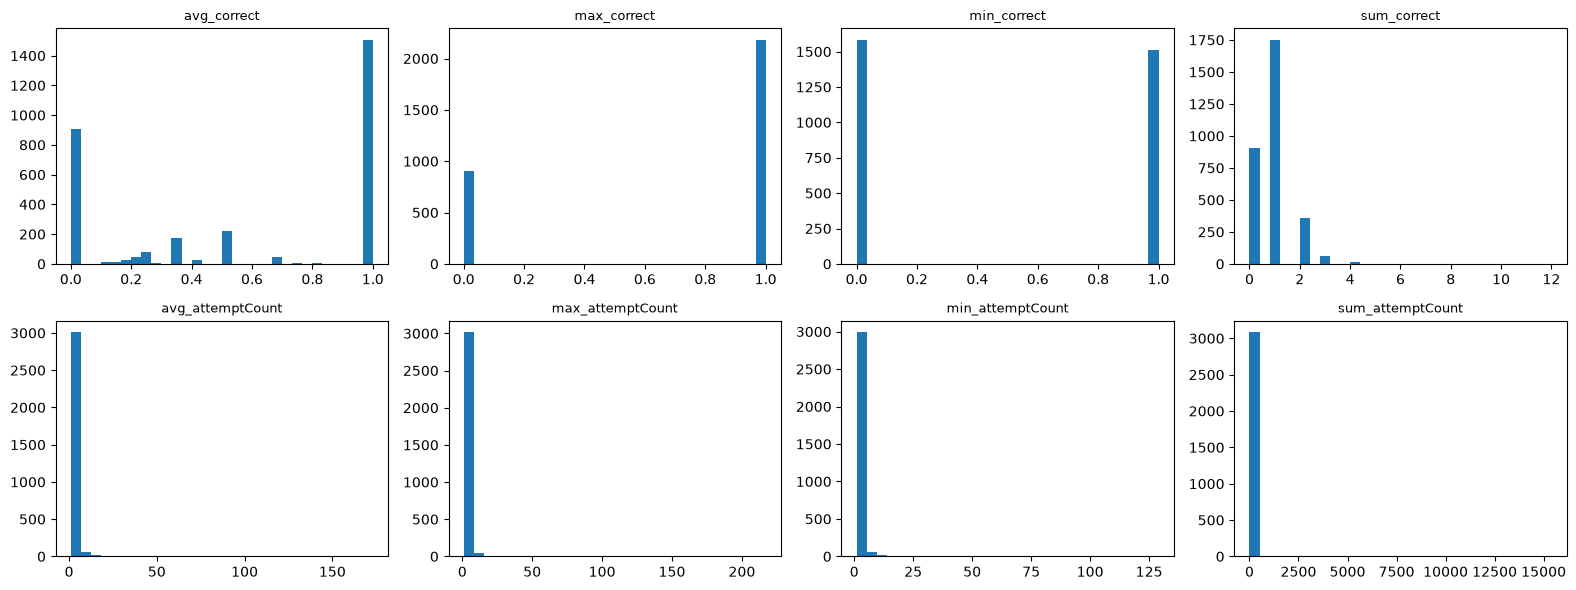

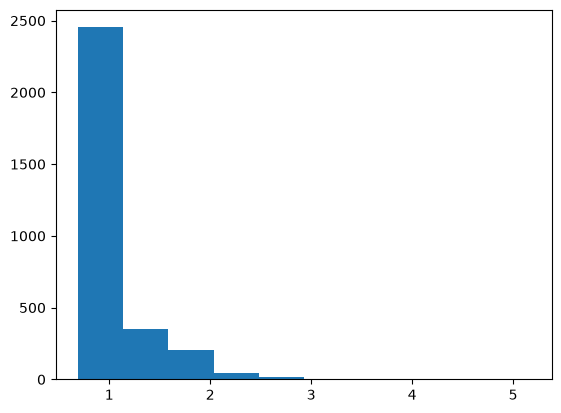

In [15]:
import numpy as np
import matplotlib.pyplot as plt

def hist_tema(base_vars, datos=X, bins=30, log_y=False):
    versiones = ["avg", "max", "min", "sum"]
    fig, ejes = plt.subplots(len(base_vars), 4, figsize=(16, 3 * len(base_vars)))
    ejes = np.atleast_2d(ejes)
    for i, base in enumerate(base_vars):
        for j, v in enumerate(versiones):
            col = f"{v}_{base}"
            ax = ejes[i, j]
            ax.hist(datos[col], bins=bins)
            ax.set_title(col, fontsize=9)
            if log_y:
                ax.set_yscale("log")
    plt.tight_layout()
    plt.show()

#Nos quedamos con avg y sum. Log a avg_attemptCount
hist_tema(["correct", "attemptCount"]) # nos quedamos con avg de las dos
plt.hist(np.log1p(X["avg_attemptCount"]));

In [16]:
n_acciones = X["sum_attemptCount"] / X["avg_attemptCount"]
print(n_acciones.describe())
print(X.loc[X["sum_attemptCount"].idxmax(), ["avg_attemptCount", "max_attemptCount", "min_attemptCount", "sum_attemptCount"]])

count    3093.000000
mean        2.186227
std         3.848049
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max       124.000000
dtype: float64
avg_attemptCount      173.0
max_attemptCount      217.0
min_attemptCount      129.0
sum_attemptCount    15397.0
Name: 639, dtype: float64


In [17]:
#RARO LOS 1500 HINTS EN SUM......
print((n_acciones == 1).mean())                 # proporción de clips con una sola acción
print((n_acciones > 10).sum(), "clips con más de 10 acciones")
print((n_acciones > 20).sum(), "clips con más de 20 acciones")

0.5140640155189137
21 clips con más de 10 acciones
6 clips con más de 20 acciones


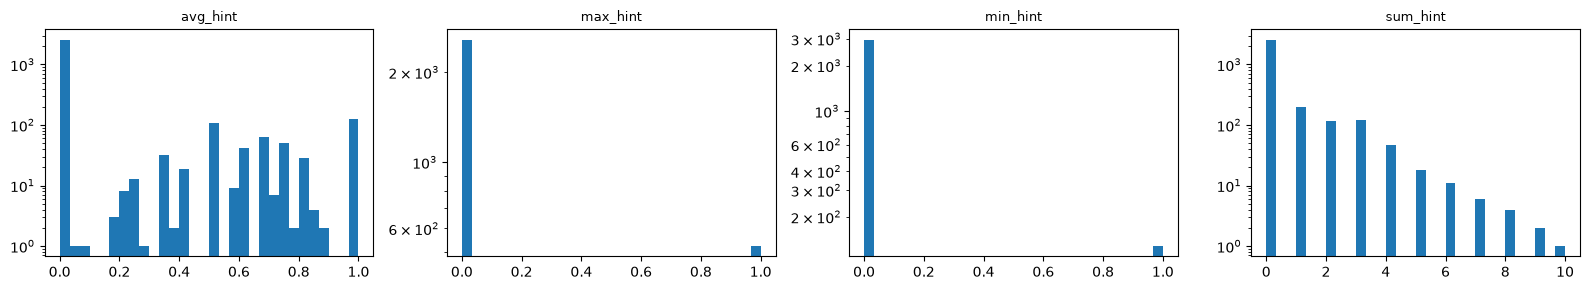

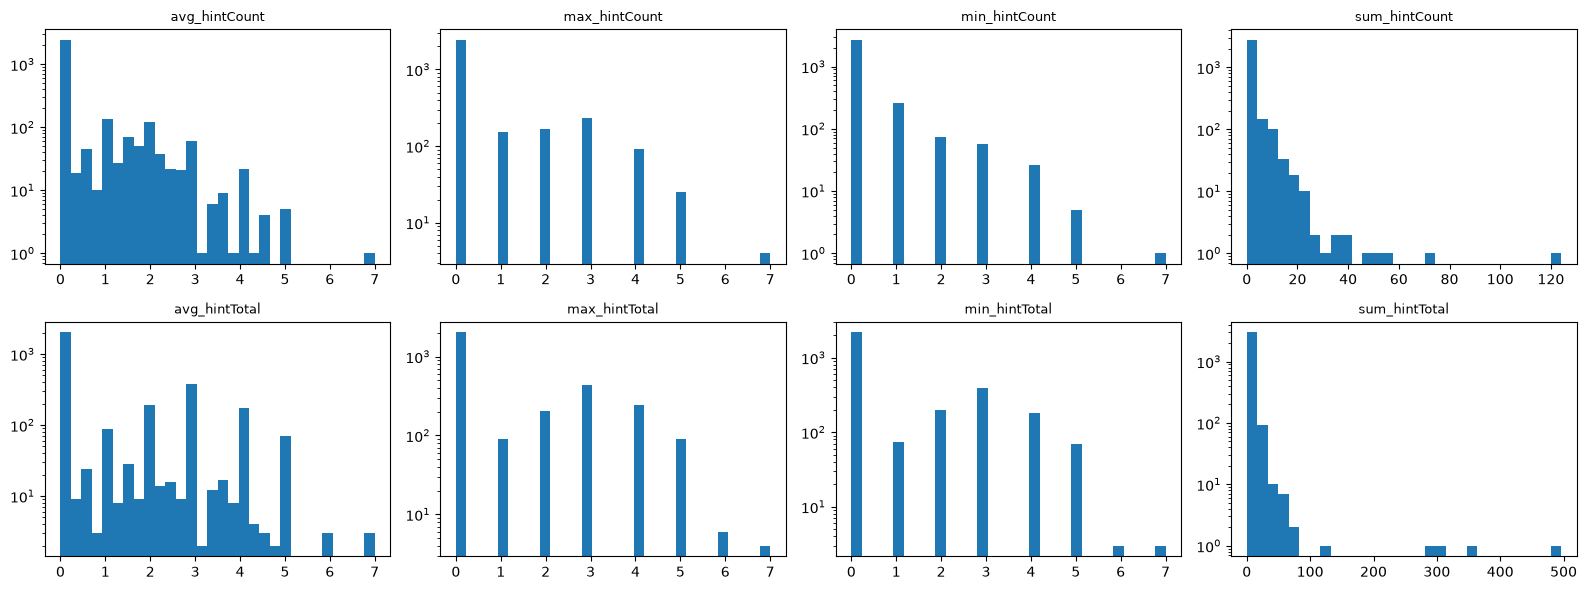

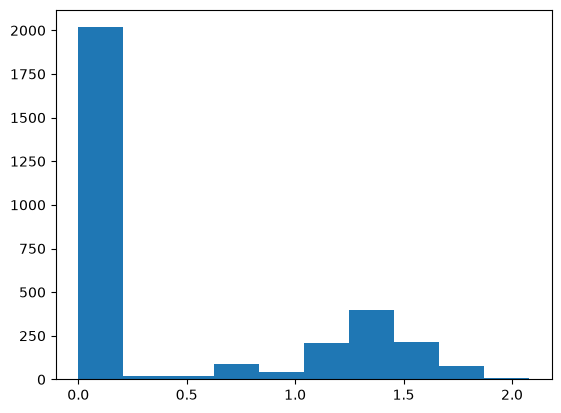

In [18]:
#avg o sum sin log
hist_tema(["hint"], log_y=True)
#avg sin log, sum con log
hist_tema(["hintCount", "hintTotal"], log_y=True)
plt.hist(np.log1p(X["avg_hintTotal"]));


(array([2.424e+03, 1.200e+02, 1.890e+02, 7.100e+01, 1.910e+02, 6.200e+01,
        2.600e+01, 5.000e+00, 4.000e+00, 1.000e+00]),
 array([0.        , 0.48283137, 0.96566275, 1.44849412, 1.93132549,
        2.41415687, 2.89698824, 3.37981962, 3.86265099, 4.34548236,
        4.82831374]),
 <BarContainer object of 10 artists>)

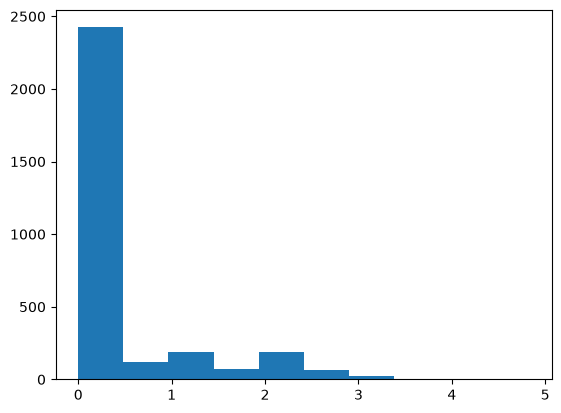

In [19]:
plt.hist(np.log1p(X["sum_hintCount"]))

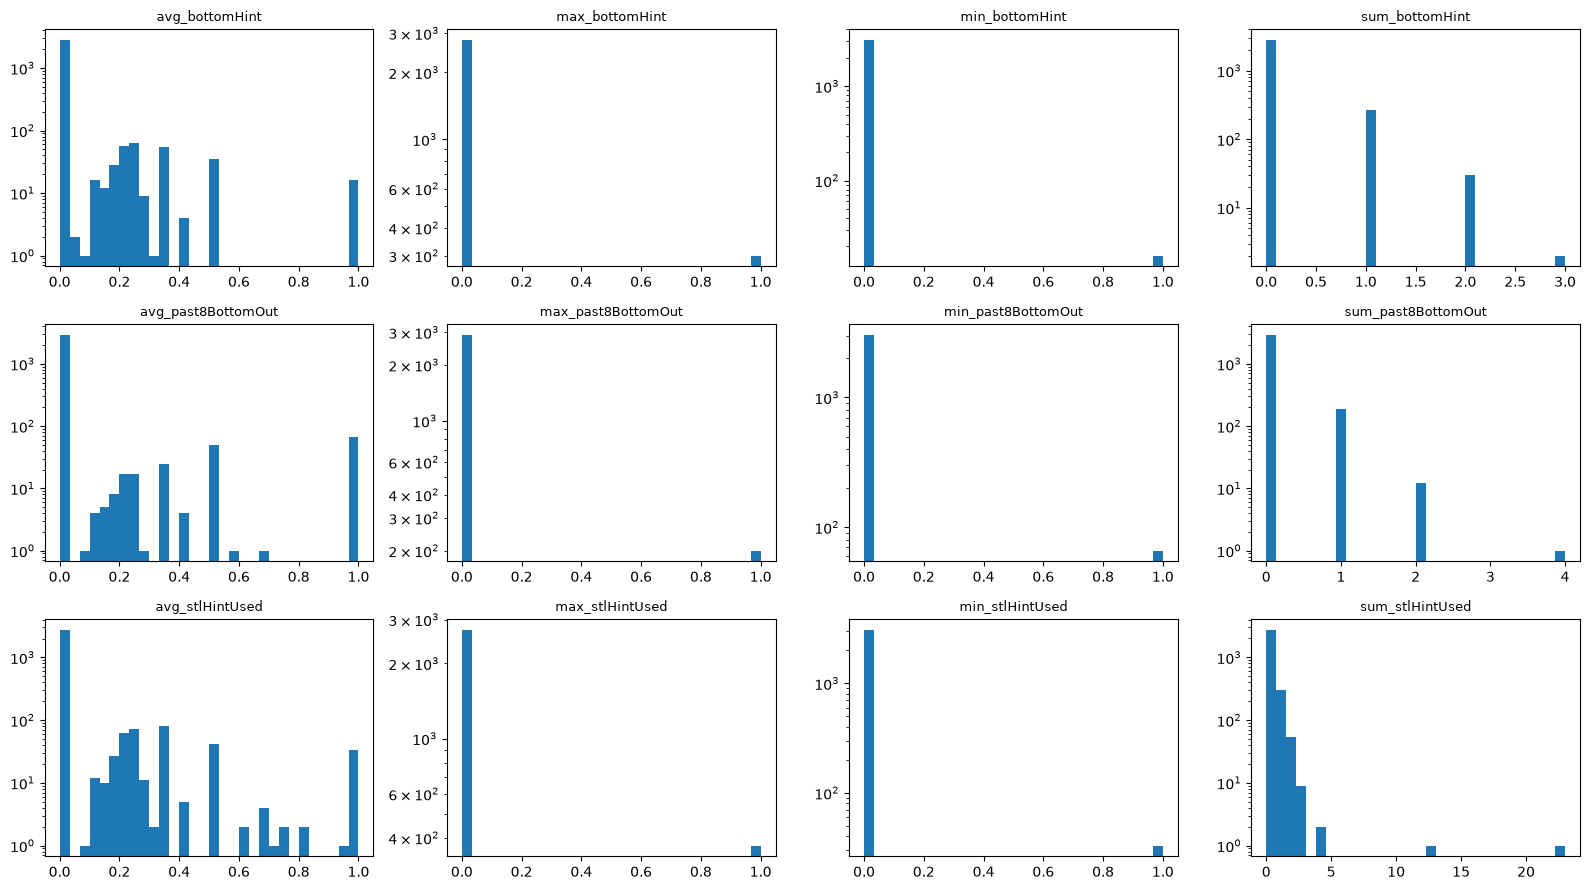

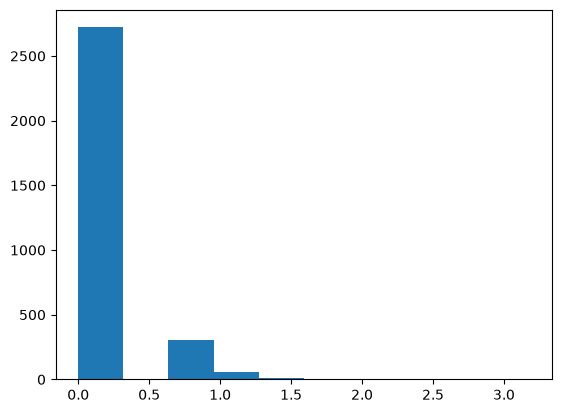

In [20]:
#avg o sum sin log (sumstlhinted log)
hist_tema(["bottomHint", "past8BottomOut", "stlHintUsed"], log_y=True)
plt.hist(np.log1p(X["sum_stlHintUsed"]));

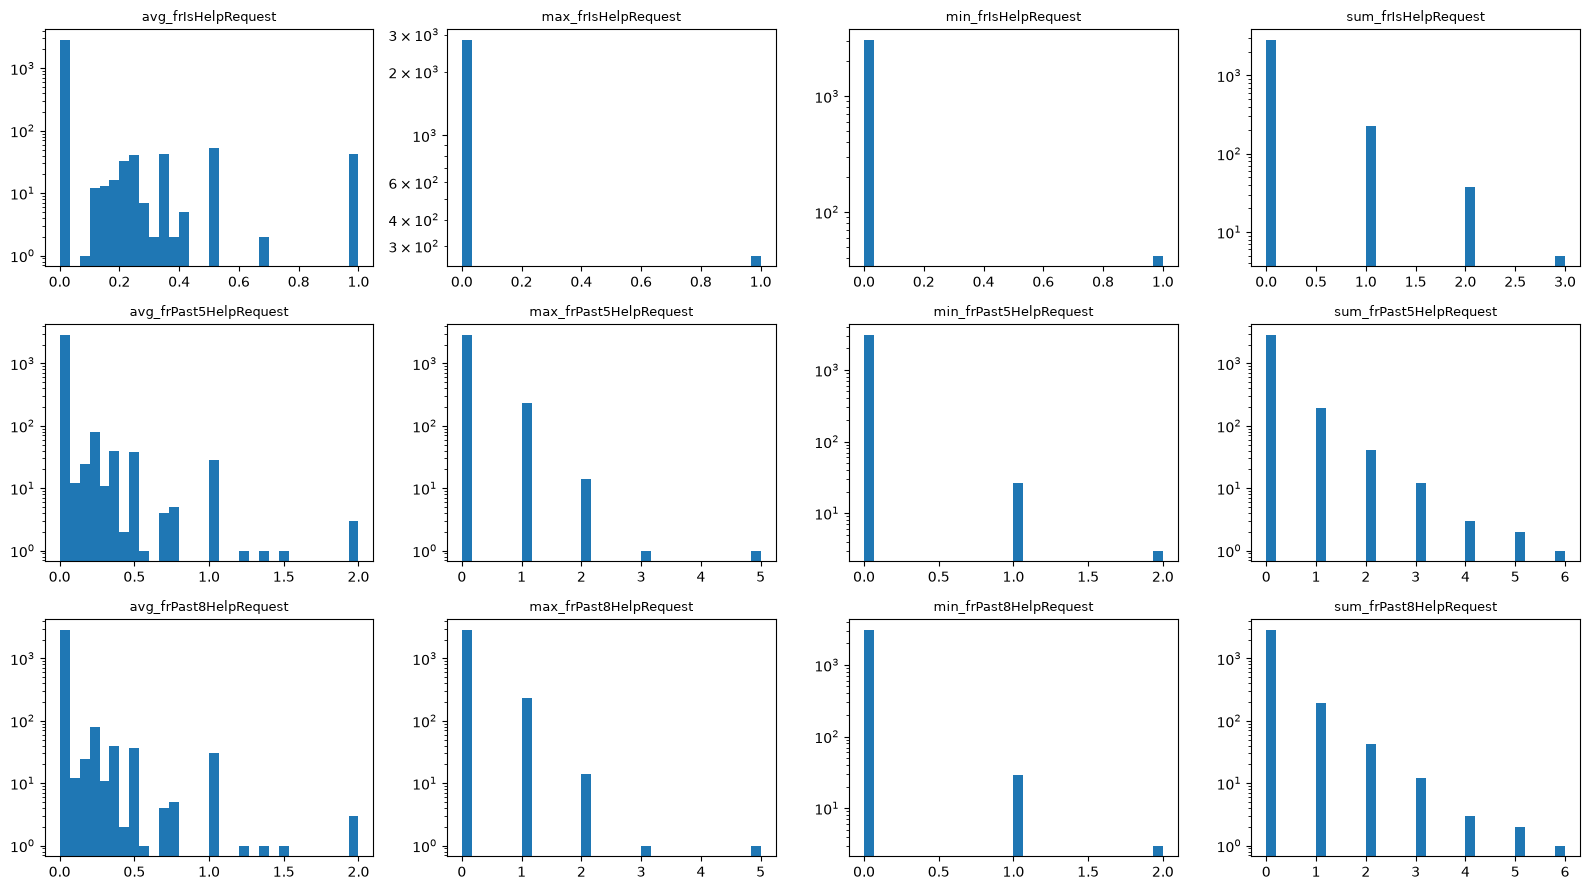

In [21]:

hist_tema(["frIsHelpRequest", "frPast5HelpRequest", "frPast8HelpRequest"], log_y=True)

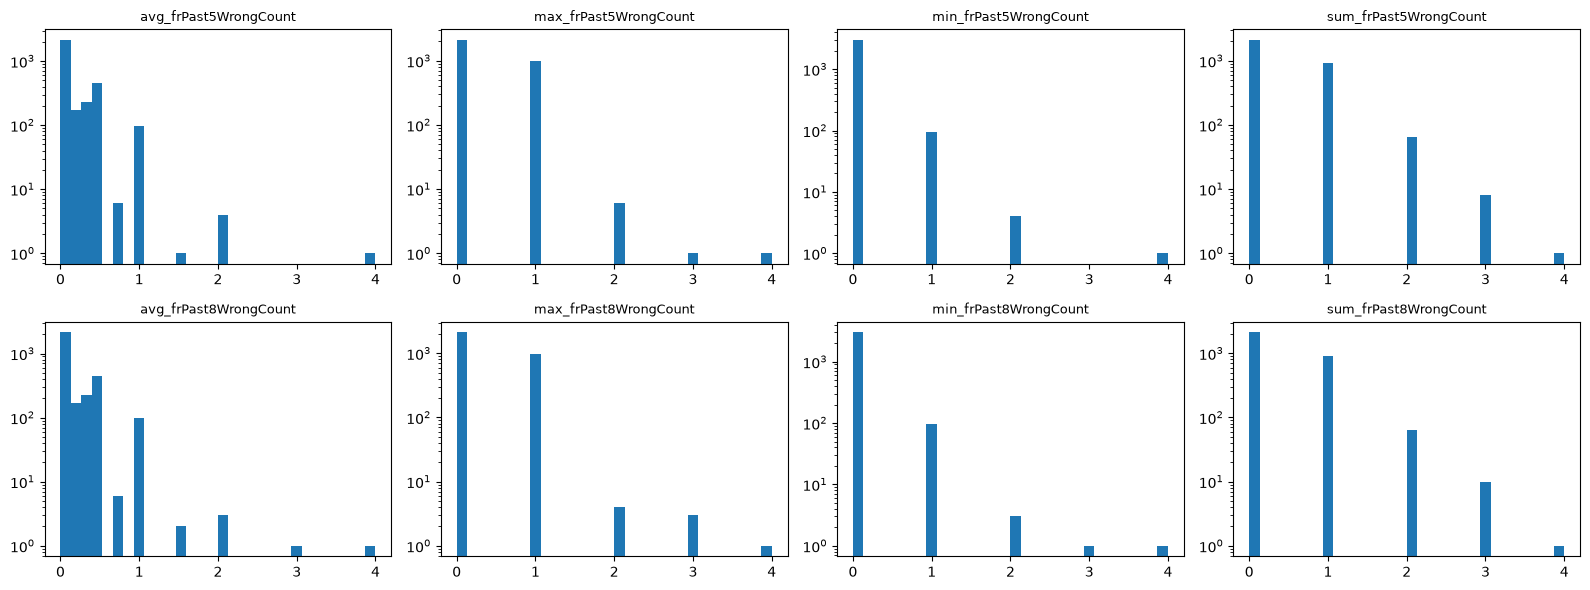

In [22]:
hist_tema(["frPast5WrongCount", "frPast8WrongCount"], bins=30, log_y=True)

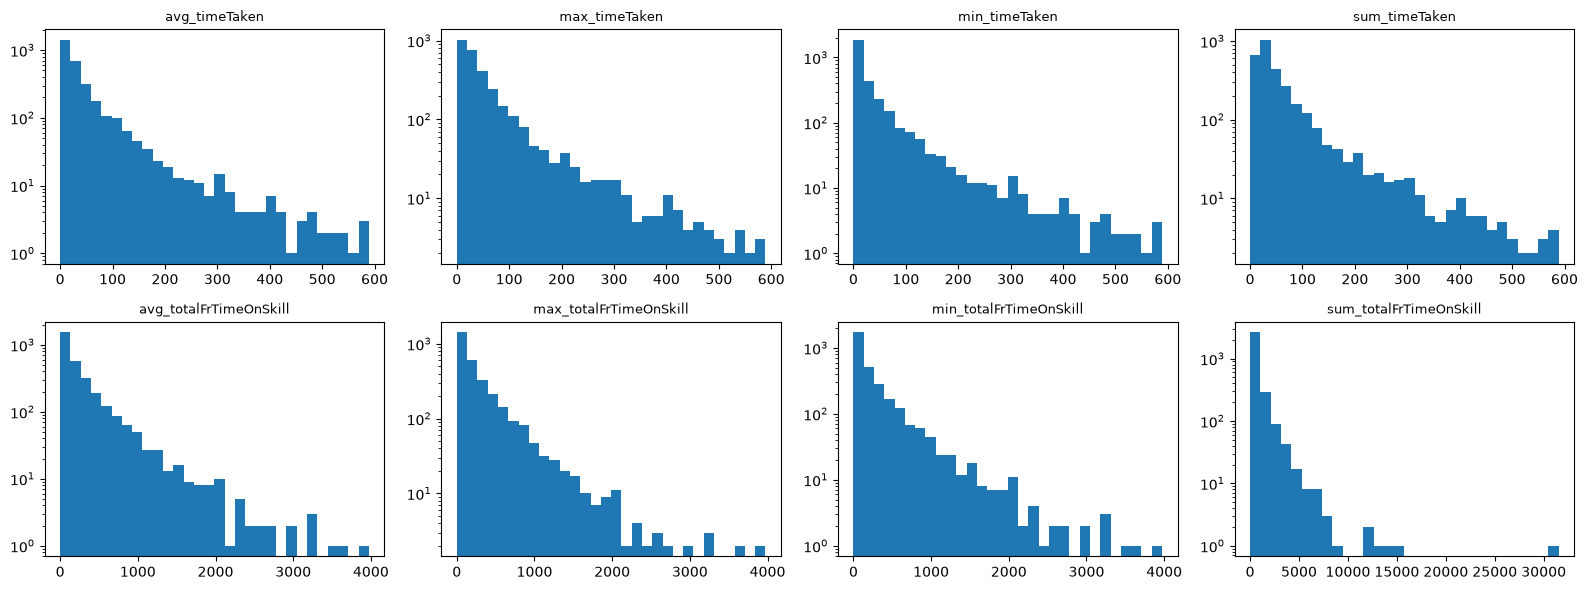

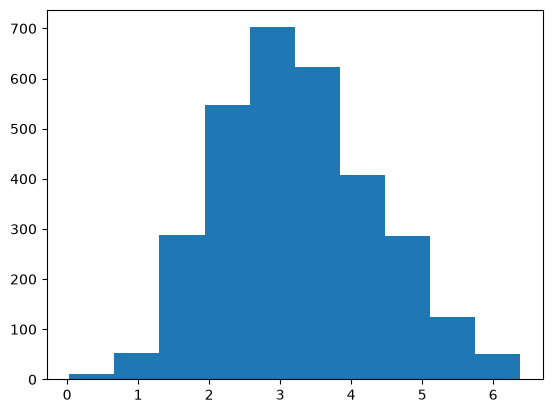

In [23]:
# sum y log 
hist_tema(["timeTaken", "totalFrTimeOnSkill"], bins=30, log_y=True)
plt.hist(np.log1p(X["avg_timeTaken"]));

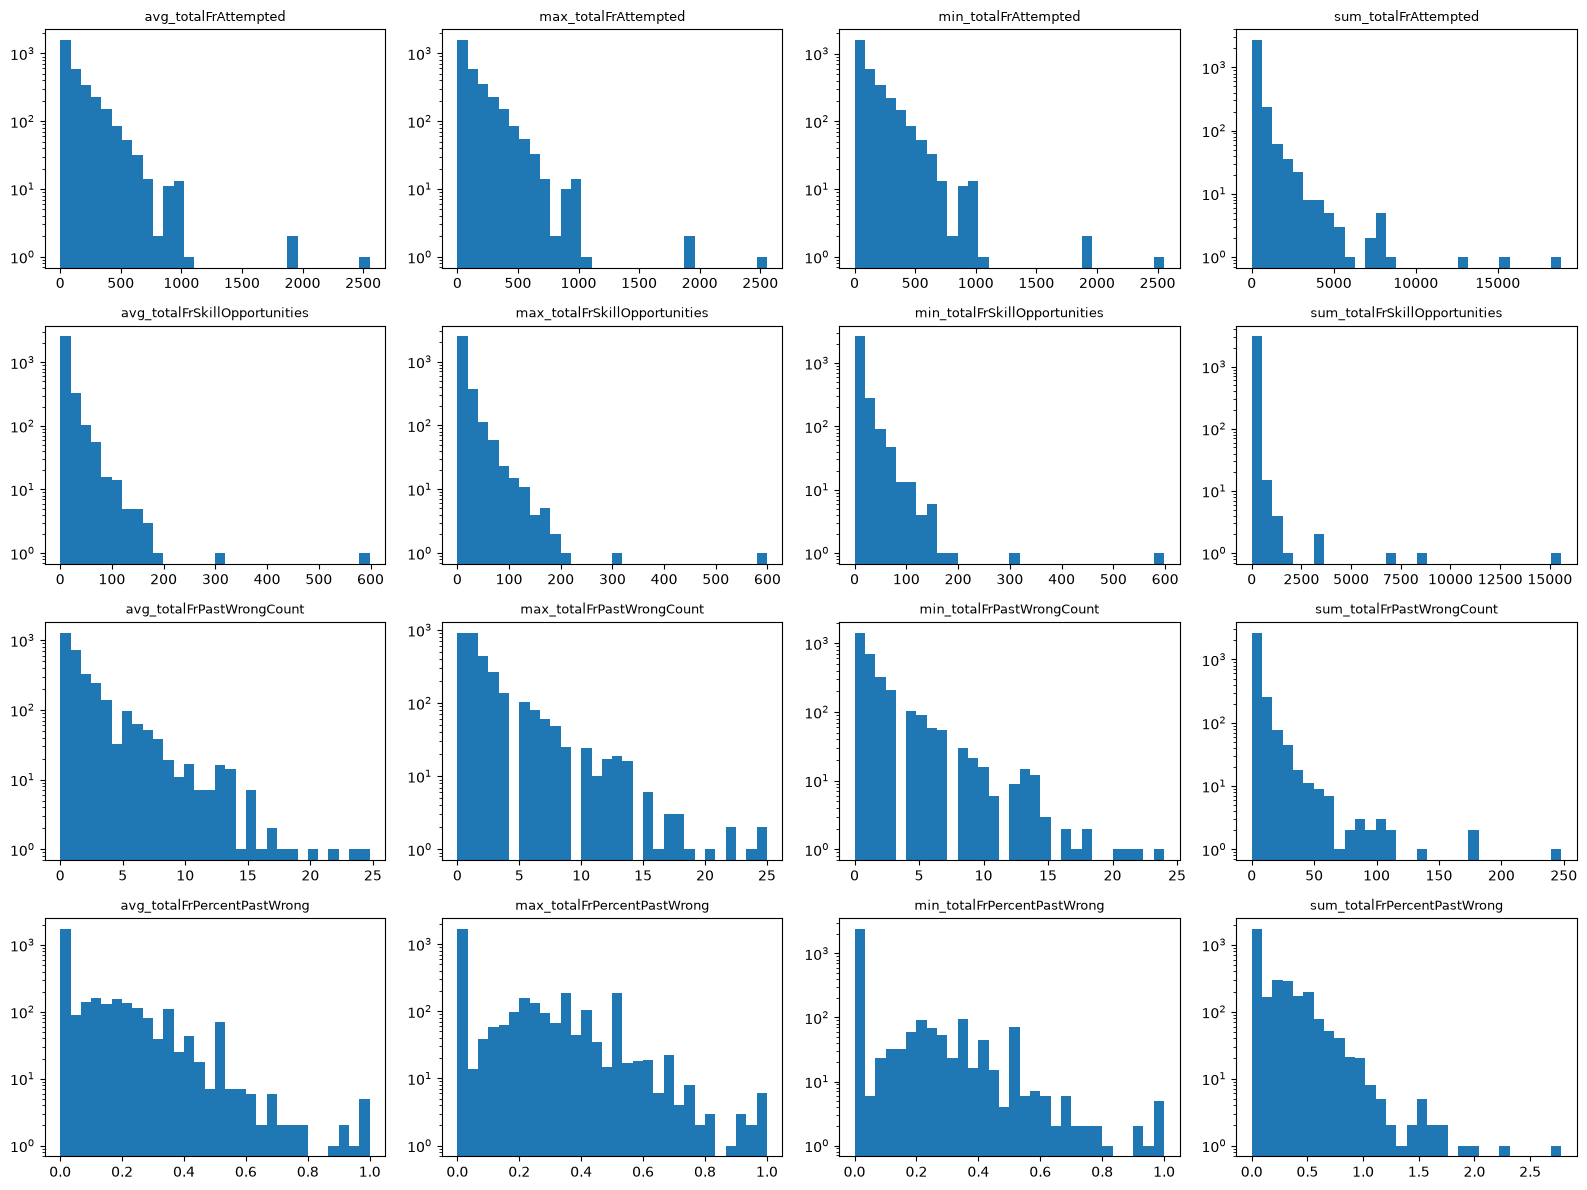

In [24]:
# avg y log en totalfrattempt, totalfrskillopports, totalpastwrongcount
hist_tema(["totalFrAttempted", "totalFrSkillOpportunities", "totalFrPastWrongCount", "totalFrPercentPastWrong"], bins=30, log_y=True)


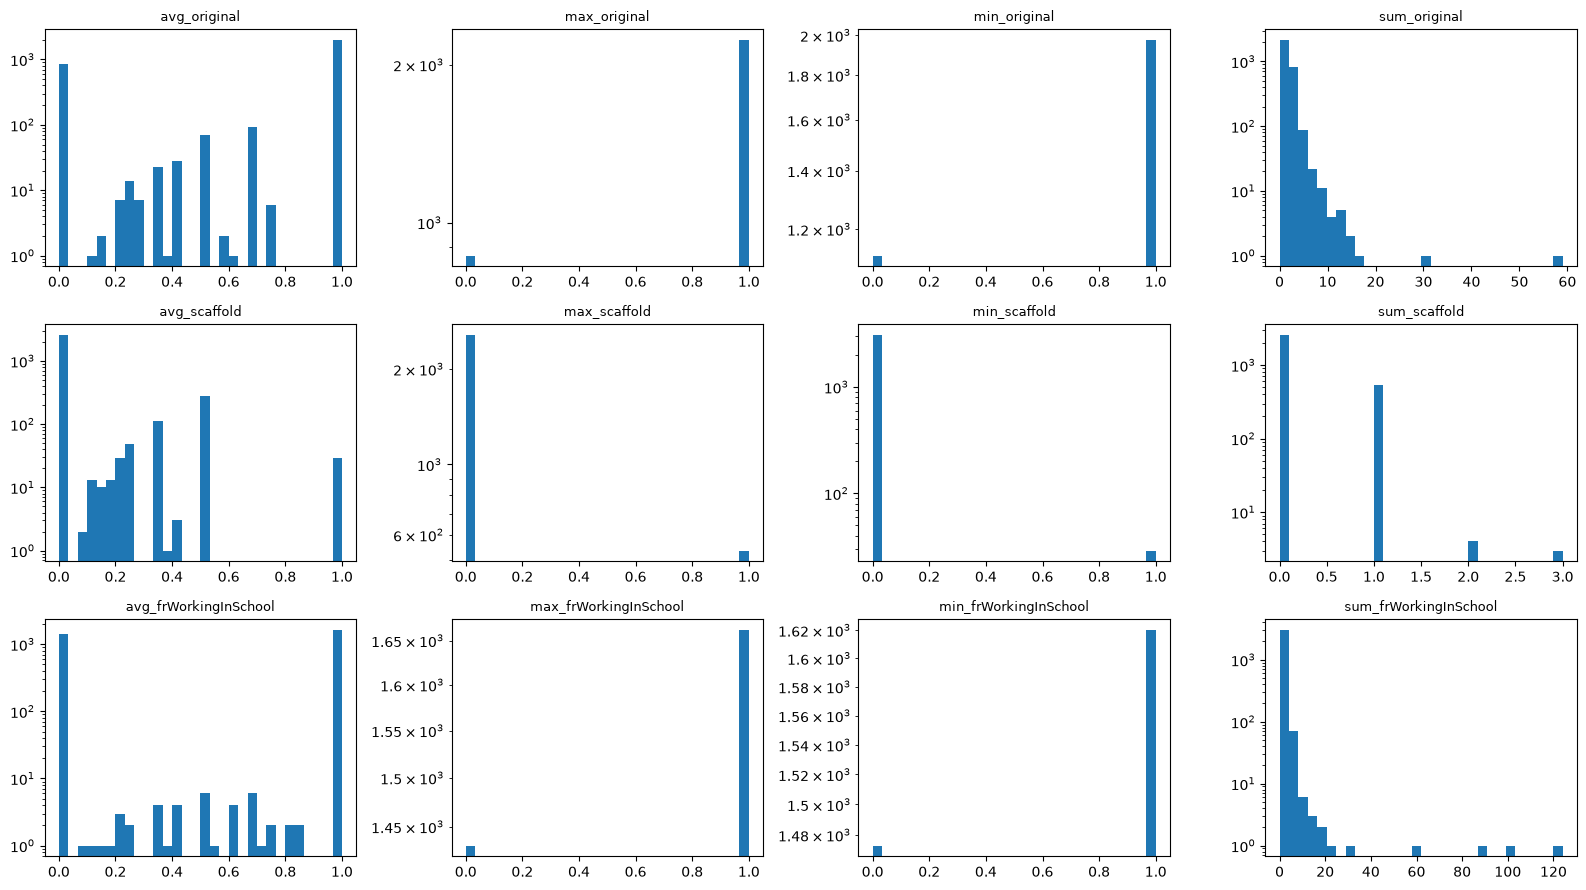

In [25]:
hist_tema(["original","scaffold", "frWorkingInSchool"], bins=30, log_y=True)

In [26]:
df_multi["urbanicity"].value_counts()

urbanicity
3    1761
1     737
2     595
Name: count, dtype: int64

In [27]:
ambas = ["correct", "attemptCount", "hint", "hintCount", "hintTotal", "bottomHint",
         "past8BottomOut", "stlHintUsed", "frIsHelpRequest", "frPast5HelpRequest",
         "frPast8HelpRequest", "scaffold", "frWorkingInSchool"]
solo_avg = ["timeTaken", "totalFrTimeOnSkill", "frPast5WrongCount", "frPast8WrongCount",
            "totalFrAttempted", "totalFrSkillOpportunities", "totalFrPastWrongCount",
            "totalFrPercentPastWrong", "original"]

cols_reducidas = [f"avg_{v}" for v in ambas + solo_avg] + [f"sum_{v}" for v in ambas]

print(len(cols_reducidas))                                   # 35
print([c for c in cols_reducidas if c not in X.columns])     # debe salir []

35
[]


In [28]:
corr = X[cols_reducidas].corr().abs()
mitad = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pares = mitad.stack().sort_values(ascending=False)
altos = pares[pares > 0.95]

print(len(altos), "parejas con correlación > 0.95 (antes: 33)")
print(altos)

3 parejas con correlación > 0.95 (antes: 33)
sum_frPast5HelpRequest  sum_frPast8HelpRequest    0.997339
avg_frPast5WrongCount   avg_frPast8WrongCount     0.997194
avg_frPast5HelpRequest  avg_frPast8HelpRequest    0.983738
dtype: float64


In [29]:
resumen = pd.DataFrame({
    "min": X[cols_reducidas].min(),
    "max": X[cols_reducidas].max(),
    "asimetria": X[cols_reducidas].skew()
})

# Todas las columnas, ordenadas de mayor a menor máximo
print(resumen.sort_values("max", ascending=False).round(2).to_string())

# Las que no admiten log1p (mínimo negativo)
print("Mínimo negativo:", resumen.index[resumen["min"] < 0].tolist())

                                min       max  asimetria
sum_attemptCount               1.00  15397.00      35.86
avg_totalFrTimeOnSkill         0.00   3972.87       3.26
avg_totalFrAttempted           0.00   2554.50       3.12
avg_totalFrSkillOpportunities  0.00    598.50       8.90
avg_timeTaken                  0.03    588.92       3.57
sum_hintTotal                  0.00    496.00      21.84
avg_attemptCount               1.00    173.00      19.12
sum_frWorkingInSchool          0.00    124.00      22.92
sum_hintCount                  0.00    124.00      10.32
avg_totalFrPastWrongCount      0.00     24.75       2.78
sum_stlHintUsed                0.00     23.00      18.58
sum_correct                    0.00     12.00       2.70
sum_hint                       0.00     10.00       3.51
avg_hintCount                  0.00      7.00       2.44
avg_hintTotal                  0.00      7.00       1.20
sum_frPast8HelpRequest         0.00      6.00       5.48
sum_frPast5HelpRequest         

In [30]:
# variables con  rango en x > 20 : aplicaremos log
cols_log = resumen[resumen["max"] > 20].index.tolist()
print(len(cols_log), cols_log)

antes   = X[cols_log].skew()
despues = np.log1p(X[cols_log]).skew()
print(pd.DataFrame({"antes": antes, "despues": despues}).round(2))

11 ['avg_attemptCount', 'avg_timeTaken', 'avg_totalFrTimeOnSkill', 'avg_totalFrAttempted', 'avg_totalFrSkillOpportunities', 'avg_totalFrPastWrongCount', 'sum_attemptCount', 'sum_hintCount', 'sum_hintTotal', 'sum_stlHintUsed', 'sum_frWorkingInSchool']
                               antes  despues
avg_attemptCount               19.12     3.04
avg_timeTaken                   3.57     0.28
avg_totalFrTimeOnSkill          3.26    -0.91
avg_totalFrAttempted            3.12    -0.46
avg_totalFrSkillOpportunities   8.90     0.28
avg_totalFrPastWrongCount       2.78     0.72
sum_attemptCount               35.86     2.39
sum_hintCount                  10.32     2.08
sum_hintTotal                  21.84     1.31
sum_stlHintUsed                18.58     3.16
sum_frWorkingInSchool          22.92     1.10


In [31]:
# 1. Completa: las 92 variables menos las 4 constantes (88). urbanicity va aparte.
cols_completa = [c for c in X.columns if c not in constantes and c != "urbanicity"]

# 2. Reducida: la de 35 columnas que ya tienes (cols_reducidas)
cols_reducida = list(cols_reducidas)

# 3. Reducida sin las ventanas de 5 (las que forman parejas casi duplicadas con las de 8)
quitar_v5 = ["sum_frPast5HelpRequest", "avg_frPast5WrongCount", "avg_frPast5HelpRequest"]
cols_reducida_v8 = [c for c in cols_reducida if c not in quitar_v5]

# 4. Columnas candidatas a log1p (grupo A de antes), escritas a mano para que sean fijas
log_reducida = ["sum_attemptCount", "avg_attemptCount", "avg_totalFrTimeOnSkill",
                "avg_totalFrAttempted", "avg_totalFrSkillOpportunities", "avg_timeTaken",
                "sum_hintTotal", "sum_frWorkingInSchool", "sum_hintCount",
                "avg_totalFrPastWrongCount", "sum_stlHintUsed"]

# Para la lista completa, la regla (máximo > 20) se aplica a sus columnas
log_completa = [c for c in cols_completa if X[c].max() > 20]

In [32]:
conjuntos = {"completa": cols_completa, "reducida": cols_reducida, "reducida_v8": cols_reducida_v8}

for nombre, lista in conjuntos.items():
    print(nombre, len(lista),
          "| faltan en X:", [c for c in lista if c not in X.columns],
          "| repetidas:", len(lista) - len(set(lista)))

print("log_reducida dentro de reducida:", all(c in cols_reducida for c in log_reducida), len(log_reducida))
print("log_completa:", len(log_completa))

completa 88 | faltan en X: [] | repetidas: 0
reducida 35 | faltan en X: [] | repetidas: 0
reducida_v8 32 | faltan en X: [] | repetidas: 0
log_reducida dentro de reducida: True 11
log_completa: 29


In [33]:
corr = X[cols_reducida_v8].corr().abs()
mitad = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
altos = mitad.stack()[lambda s: s > 0.95]
print(len(altos), "parejas con correlación > 0.95")

0 parejas con correlación > 0.95


In [34]:
print(df_modelo["urbanicity"].value_counts().sort_index())
print(pd.crosstab(df_modelo["urbanicity"], df_modelo["target"]))
print(pd.crosstab(df_modelo["urbanicity"], df_modelo["target"], normalize="index").round(3))

urbanicity
1     737
2     595
3    1761
Name: count, dtype: int64
target      boredom  concentration  confusion  frustration
urbanicity                                                
1               199            416         56           66
2                43            478         48           26
3                66           1658         17           20
target      boredom  concentration  confusion  frustration
urbanicity                                                
1             0.270          0.564      0.076        0.090
2             0.072          0.803      0.081        0.044
3             0.037          0.942      0.010        0.011
